<a href="https://colab.research.google.com/github/ayeshaalamexe/ds311-phishguard/blob/main/notebooks/02_data_lead.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
!pip install ucimlrepo -q

In [31]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

pd.set_option("display.max_rows", 100)
SEED = 42

In [32]:
from ucimlrepo import fetch_ucirepo

d = fetch_ucirepo(id=967)
X = d.data.features
y = d.data.targets
df = pd.concat([X, y], axis=1)

LABEL = "label"
print(df.shape)
print(df[LABEL].value_counts())
df.head()

(235795, 55)
label
1    134850
0    100945
Name: count, dtype: int64


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [33]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "missing": df.isna().sum(),
    "example": df.iloc[0].astype(str)
})
info

,dtype,n_unique,missing,example
URL,object,235370,0,https://www.southbankmosaics.com
URLLength,int64,482,0,31
Domain,object,220086,0,www.southbankmosaics.com
DomainLength,int64,101,0,24
IsDomainIP,int64,2,0,0
TLD,object,695,0,com
URLSimilarityIndex,float64,36360,0,100.0
CharContinuationRate,float64,898,0,1.0
TLDLegitimateProb,float64,465,0,0.5229071
URLCharProb,float64,227421,0,0.061933179


In [34]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate URLs:", df["URL"].duplicated().sum())

dup = df[df["URL"].duplicated(keep=False)]
print("Rows with a repeated URL:", len(dup))

labels_per_url = dup.groupby("URL")[LABEL].nunique()
print("URLs with conflicting labels:", (labels_per_url > 1).sum())
print(dup[LABEL].value_counts())

Missing values: 0
Duplicate rows: 0
Duplicate URLs: 425
Rows with a repeated URL: 850
URLs with conflicting labels: 0
label
0    850
Name: count, dtype: int64


In [35]:
before = len(df)
df_clean = df.drop_duplicates(subset="URL", keep="first").reset_index(drop=True)
print(before, "->", len(df_clean), "rows. Removed:", before - len(df_clean))
print(df_clean[LABEL].value_counts())

df_clean["is_phish"] = (df_clean[LABEL] == 0).astype(int)

235795 -> 235370 rows. Removed: 425
label
1    134850
0    100520
Name: count, dtype: int64


In [36]:
text_cols = df_clean.select_dtypes(include="object").columns.tolist()
print("Text columns:", text_cols)

num_cols = []
for c in df_clean.select_dtypes("number").columns:
    if c != LABEL and c != "is_phish":
        num_cols.append(c)
print("Number of numeric features:", len(num_cols))

const = [c for c in num_cols if df_clean[c].nunique() <= 1]
print("Constant columns:", const)

Text columns: ['URL', 'Domain', 'TLD', 'Title']
Number of numeric features: 50
Constant columns: []


label
1    0.573
0    0.427
Name: proportion, dtype: float64


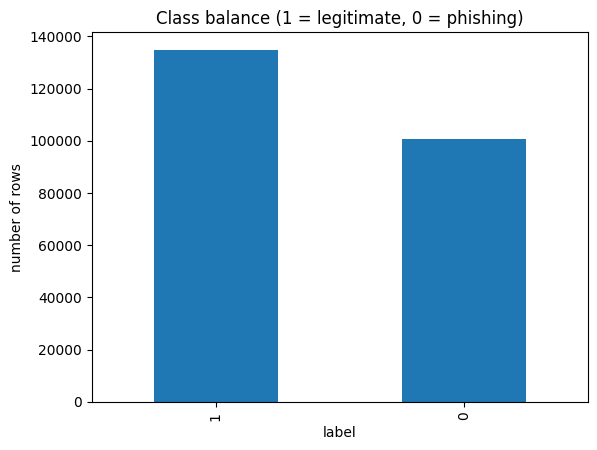

In [37]:
counts = df_clean[LABEL].value_counts()
print(df_clean[LABEL].value_counts(normalize=True).round(3))

counts.plot(kind="bar", title="Class balance (1 = legitimate, 0 = phishing)")
plt.ylabel("number of rows")
plt.show()

In [38]:
group_a = ["URLLength", "DomainLength", "IsDomainIP", "TLDLength", "NoOfSubDomain",
           "CharContinuationRate", "HasObfuscation", "NoOfObfuscatedChar", "ObfuscationRatio",
           "NoOfLettersInURL", "LetterRatioInURL", "NoOfDegitsInURL", "DegitRatioInURL",
           "NoOfEqualsInURL", "NoOfQMarkInURL", "NoOfAmpersandInURL",
           "NoOfOtherSpecialCharsInURL", "SpacialCharRatioInURL", "IsHTTPS"]
group_a = [c for c in group_a if c in df_clean.columns]

group_b = ["URLSimilarityIndex", "TLDLegitimateProb", "URLCharProb"]

dd = info.copy()
dd["url_computable"] = "no (needs webpage)"
for c in group_a + ["URL", "Domain", "TLD"]:
    dd.loc[c, "url_computable"] = "yes"
for c in group_b:
    dd.loc[c, "url_computable"] = "check"

dd["use"] = "keep"
for c in ["URL", "Domain", "TLD", "Title"]:
    dd.loc[c, "use"] = "text-only"
dd.loc["URLSimilarityIndex", "use"] = "leakage suspect"
dd.loc[LABEL, "use"] = "target"

dd["meaning"] = ""
dd.to_csv("data_dictionary.csv")
dd

,dtype,n_unique,missing,example,url_computable,use,meaning
URL,object,235370,0,https://www.southbankmosaics.com,yes,text-only,
URLLength,int64,482,0,31,yes,keep,
Domain,object,220086,0,www.southbankmosaics.com,yes,text-only,
DomainLength,int64,101,0,24,yes,keep,
IsDomainIP,int64,2,0,0,yes,keep,
TLD,object,695,0,com,yes,text-only,
URLSimilarityIndex,float64,36360,0,100.0,check,leakage suspect,
CharContinuationRate,float64,898,0,1.0,yes,keep,
TLDLegitimateProb,float64,465,0,0.5229071,check,keep,
URLCharProb,float64,227421,0,0.061933179,check,keep,


label                            0       1
URLLength                   45.703  26.229
DomainLength                24.444  19.229
IsDomainIP                   0.006   0.000
TLDLength                    2.819   2.723
NoOfSubDomain                1.169   1.162
CharContinuationRate         0.729   0.933
HasObfuscation               0.005   0.000
NoOfObfuscatedChar           0.058   0.000
ObfuscationRatio             0.000   0.000
NoOfLettersInURL            28.089  12.933
LetterRatioInURL             0.568   0.477
NoOfDegitsInURL              4.324   0.051
DegitRatioInURL              0.064   0.002
NoOfEqualsInURL              0.146   0.000
NoOfQMarkInURL               0.069   0.000
NoOfAmpersandInURL           0.059   0.000
NoOfOtherSpecialCharsInURL   3.800   1.245
SpacialCharRatioInURL        0.083   0.048
IsHTTPS                      0.491   1.000


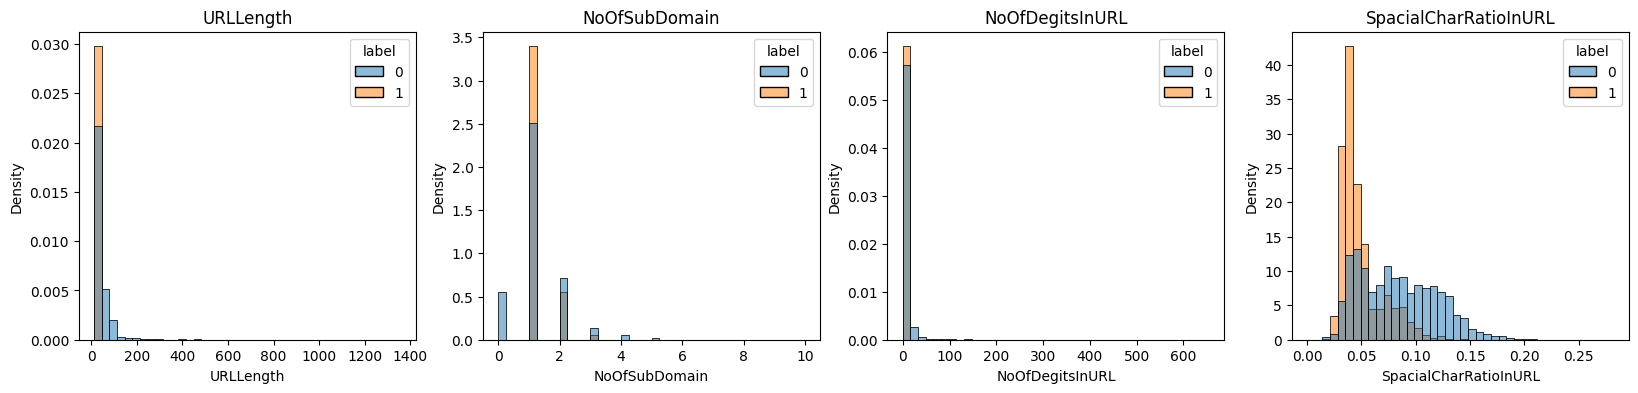

In [39]:
print(df_clean.groupby(LABEL)[group_a].mean().T.round(3))

small = df_clean.sample(50000, random_state=SEED)
cols = ["URLLength", "NoOfSubDomain", "NoOfDegitsInURL", "SpacialCharRatioInURL"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for i in range(4):
    sns.histplot(data=small, x=cols[i], hue=LABEL, bins=40,
                 stat="density", common_norm=False, ax=axes[i])
    axes[i].set_title(cols[i])
plt.show()

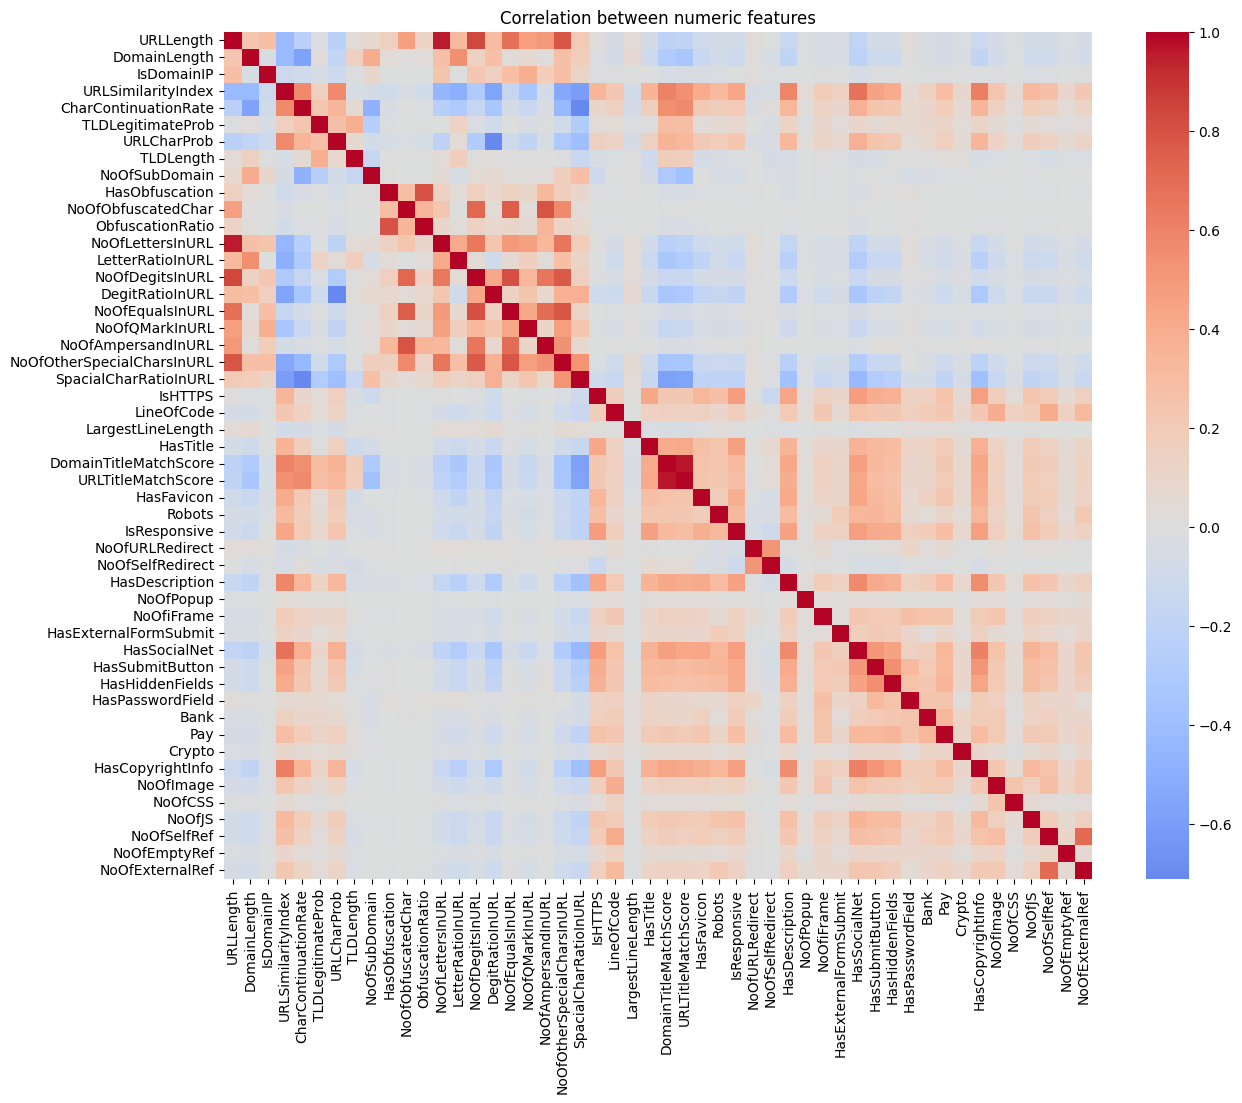

Highly correlated pairs: 2
('URLLength', 'NoOfLettersInURL', np.float64(0.956))
('DomainTitleMatchScore', 'URLTitleMatchScore', np.float64(0.961))


In [40]:
corr = df_clean[num_cols].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()

high_pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.9:
            high_pairs.append((corr.columns[i], corr.columns[j], round(corr.iloc[i, j], 3)))
print("Highly correlated pairs:", len(high_pairs))
for p in high_pairs:
    print(p)

In [41]:
phish_len = df_clean[df_clean[LABEL] == 0]["URLLength"]
legit_len = df_clean[df_clean[LABEL] == 1]["URLLength"]

u, p = stats.mannwhitneyu(phish_len, legit_len, alternative="two-sided")
effect = u / (len(phish_len) * len(legit_len))

print("Median length, phishing:", phish_len.median())
print("Median length, legitimate:", legit_len.median())
print("p-value:", p)
print("Effect size:", round(effect, 3))

Median length, phishing: 34.0
Median length, legitimate: 26.0
p-value: 0.0
Effect size: 0.732


In [42]:
scan, _ = train_test_split(df_clean, train_size=50000,
                           stratify=df_clean[LABEL], random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scores = {}
for c in num_cols:
    tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    scores[c] = cross_val_score(tree, scan[[c]], scan[LABEL], cv=cv, scoring="roc_auc").mean()

leak = pd.Series(scores).sort_values(ascending=False)
print(leak.head(15).round(4))

suspects = leak[leak > 0.95].index.tolist()
print("Suspects:", suspects)

URLSimilarityIndex            0.9955
LineOfCode                    0.9894
NoOfExternalRef               0.9848
NoOfImage                     0.9815
NoOfJS                        0.9735
NoOfSelfRef                   0.9711
NoOfCSS                       0.9555
HasSocialNet                  0.8950
HasCopyrightInfo              0.8760
LargestLineLength             0.8532
HasDescription                0.8466
NoOfOtherSpecialCharsInURL    0.8207
SpacialCharRatioInURL         0.7998
DomainTitleMatchScore         0.7994
HasSubmitButton               0.7889
dtype: float64
Suspects: ['URLSimilarityIndex', 'LineOfCode', 'NoOfExternalRef', 'NoOfImage', 'NoOfJS', 'NoOfSelfRef', 'NoOfCSS']


In [43]:
url_no_https = [c for c in group_a if c != "IsHTTPS"]
print("With IsHTTPS:   ", round(cv_auc(group_a), 4))
print("Without IsHTTPS:", round(cv_auc(url_no_https), 4))

With IsHTTPS:    0.9907
Without IsHTTPS: 0.8556


In [44]:
def cv_auc(cols):
    tree = DecisionTreeClassifier(max_depth=5, random_state=SEED)
    return cross_val_score(tree, df_clean[cols], df_clean[LABEL], cv=cv, scoring="roc_auc").mean()

no_url_sim = [c for c in num_cols if c != "URLSimilarityIndex"]
no_suspect = [c for c in num_cols if c not in suspects]

print("All numeric features:       ", round(cv_auc(num_cols), 4))
print("Without URLSimilarityIndex: ", round(cv_auc(no_url_sim), 4))
print("Without all suspects:       ", round(cv_auc(no_suspect), 4))
print("URL-only features:          ", round(cv_auc(group_a), 4))

All numeric features:        1.0
Without URLSimilarityIndex:  0.9973
Without all suspects:        0.9954
URL-only features:           0.9907


In [45]:
train, test = train_test_split(df_clean, test_size=0.2,
                               stratify=df_clean[LABEL], random_state=SEED)
print("Train:", train.shape, "Test:", test.shape)

def evaluate(model, cols, name):
    model.fit(train[cols], train["is_phish"])
    pred = model.predict(test[cols])
    prob = model.predict_proba(test[cols])[:, 1]
    print(name, "-", len(cols), "features")
    print(classification_report(test["is_phish"], pred,
                                target_names=["legitimate", "phishing"], digits=4))
    print("Confusion matrix (rows = true, columns = predicted):")
    print(confusion_matrix(test["is_phish"], pred))
    print("ROC-AUC:", round(roc_auc_score(test["is_phish"], prob), 4))
    print()

evaluate(DecisionTreeClassifier(max_depth=5, random_state=SEED), num_cols, "Decision tree, all features")
evaluate(DecisionTreeClassifier(max_depth=5, random_state=SEED), no_suspect, "Decision tree, no suspects")
evaluate(DecisionTreeClassifier(max_depth=5, random_state=SEED), group_a, "Decision tree, URL-only")
evaluate(GaussianNB(), no_suspect, "Naive Bayes, no suspects")
evaluate(GaussianNB(), group_a, "Naive Bayes, URL-only")

Train: (188296, 56) Test: (47074, 56)
Decision tree, all features - 50 features
              precision    recall  f1-score   support

  legitimate     1.0000    1.0000    1.0000     26970
    phishing     1.0000    1.0000    1.0000     20104

    accuracy                         1.0000     47074
   macro avg     1.0000    1.0000    1.0000     47074
weighted avg     1.0000    1.0000    1.0000     47074

Confusion matrix (rows = true, columns = predicted):
[[26970     0]
 [    0 20104]]
ROC-AUC: 1.0

Decision tree, no suspects - 43 features
              precision    recall  f1-score   support

  legitimate     0.9862    0.9894    0.9878     26970
    phishing     0.9858    0.9814    0.9836     20104

    accuracy                         0.9860     47074
   macro avg     0.9860    0.9854    0.9857     47074
weighted avg     0.9860    0.9860    0.9860     47074

Confusion matrix (rows = true, columns = predicted):
[[26685   285]
 [  373 19731]]
ROC-AUC: 0.9952

Decision tree, URL-only - 

In [46]:
df_clean.to_csv("clean_data.csv", index=False)
leak.to_csv("leakage_scan.csv")

sample_small, _ = train_test_split(df_clean, train_size=5000,
                                   stratify=df_clean[LABEL], random_state=SEED)
sample_small.to_csv("sample_5000.csv", index=False)
print("Saved all files.")

Saved all files.
